In [1]:
import csv
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from torchinfo import summary
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.preprocessing import StandardScaler

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

embed_sizes={"dinov2_vits14": 384,
        "dinov2_vitb14": 768,
        "dinov2_vitl14": 1024,
        "dinov2_vitg14": 1536}

IMAGENET_DEFAULT_MEAN = (0.485, 0.456, 0.406)
IMAGENET_DEFAULT_STD = (0.229, 0.224, 0.225)

patch_num_h=16
patch_num_w=16
img_size=224

eval_model="dinov2_vits14"
eval_model_path="../models/dinobloom-s.pth"

#eval_model = "dinov2_vitg14"
#eval_model_path = "../models/DinoBloom-G.pth"

In [2]:
def get_dino_bloom(modelpath="../models/dinobloom-s.pth",modelname="dinov2_vits14"):
    # load the original DINOv2 model with the correct architecture and parameters.
    model = torch.hub.load(
    "../external/DinoBloom",  # local directory containing hubconf.py
    modelname,       # entrypoint function in hubconf.py
    source="local",
    pretrained=False,      # do not download Meta's LVD-142M DINOv2 weights
    )
    # load finetuned weights
    pretrained = torch.load(modelpath, map_location=torch.device('cpu'))
    # make correct state dict for loading
    new_state_dict = {}
    for key, value in pretrained['teacher'].items():
        if 'dino_head' in key or "ibot_head" in key:
            pass
        else:
            new_key = key.replace('backbone.', '')
            new_state_dict[new_key] = value

    #corresponds to 224x224 image. patch size=14x14 => 16*16 patches
    pos_embed = nn.Parameter(torch.zeros(1, 257, embed_sizes[modelname]))
    model.pos_embed = pos_embed

    model.load_state_dict(new_state_dict, strict=True)
    return model

model=get_dino_bloom(modelpath=eval_model_path, modelname=eval_model)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_DEFAULT_MEAN, IMAGENET_DEFAULT_STD),
])

/mnt/Dati/Projects/training-free-improvement-hematology-fm/notebooks/../external/DinoBloom/dinov2/layers/attention.py:31: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/mnt/Dati/Projects/training-free-improvement-hematology-fm/notebooks/../external/DinoBloom/dinov2/layers/block.py:57: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
/mnt/Dati/Projects/training-free-improvement-hematology-fm/notebooks/../external/DinoBloom/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")


In [3]:
print(model)

#summary(model, input_size=(4, 3, 224, 224), col_names=["input_size", "output_size", "num_params", "trainable"], depth=3)

DinoVisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 384, kernel_size=(14, 14), stride=(14, 14))
    (norm): Identity()
  )
  (blocks): ModuleList(
    (0-11): 12 x NestedTensorBlock(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True, bias=True)
      (attn): MemEffAttention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): LayerScale()
      (drop_path1): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True, bias=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=1536, out_features=384, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
      (ls2): LayerScale()
      (drop_path2): Ide

In [4]:
paths=np.random.choice(list(Path("../external/segmentation_WBC/Dataset 2").glob("*.bmp")),4)
images_for_plotting = [Image.open(img_path).convert('RGB').resize((img_size, img_size)) for img_path in paths]
imgs_tensor = torch.stack([transform(Image.open(img_path).convert('RGB').resize((img_size,img_size))).to(device) for img_path in paths])

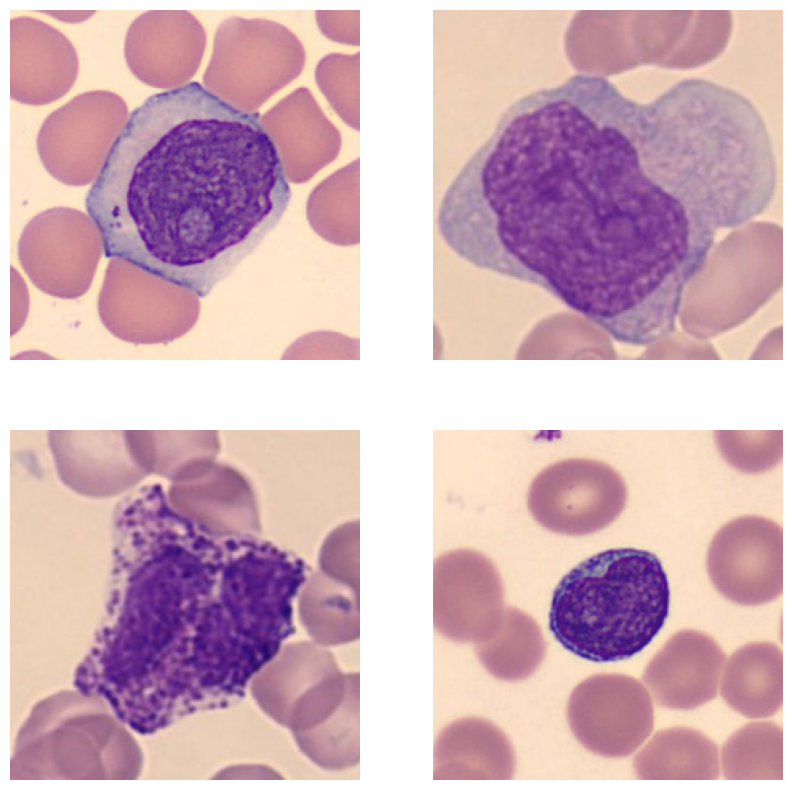

In [5]:
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
for i, ax in enumerate(axs.flat):
    #print(Path(paths[i]).stem)
    ax.imshow(images_for_plotting[i])
    ax.axis('off')  # Remove axis

In [6]:
model.to(device)
model.eval()

with torch.no_grad():
    features_dict = model.forward_features(imgs_tensor)
    patch_token = features_dict['x_norm_patchtokens']
    cls_token = features_dict['x_norm_clstoken']
    reg_token = features_dict['x_norm_regtokens']

print(f"features_dict keys: {features_dict.keys()}")
print(f"patch tokens shape: {patch_token.shape}")
print(f"cls tokens shape: {cls_token.shape}")
print(f"reg tokens shape: {reg_token.shape}")

features_dict keys: dict_keys(['x_norm_clstoken', 'x_norm_regtokens', 'x_norm_patchtokens', 'x_prenorm', 'masks'])
patch tokens shape: torch.Size([4, 256, 384])
cls tokens shape: torch.Size([4, 384])
reg tokens shape: torch.Size([4, 0, 384])


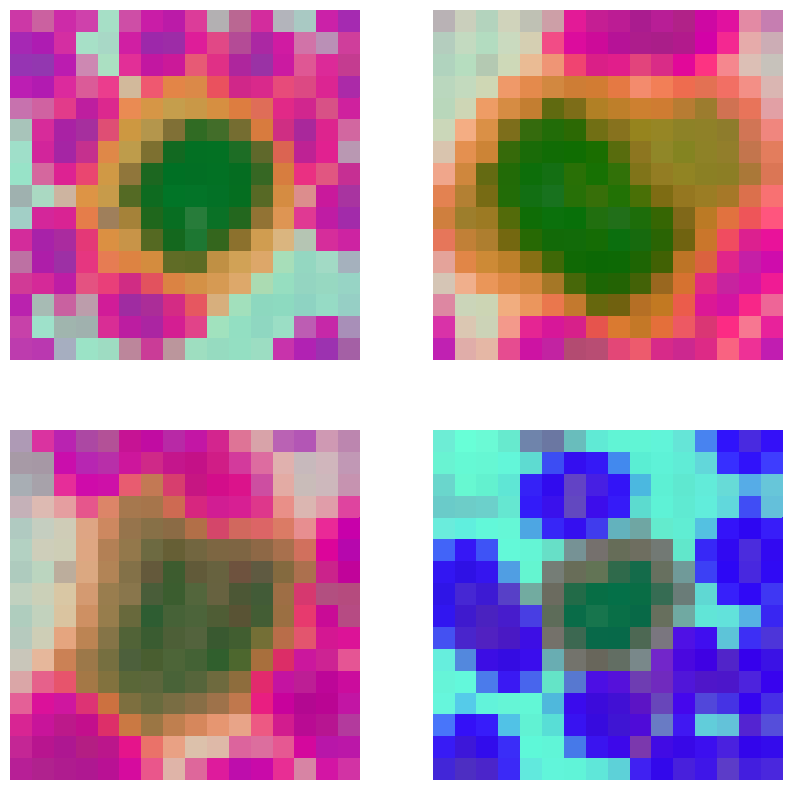

In [7]:
# PCA visualization of patch tokens
features = patch_token.reshape(len(paths) * patch_num_h*patch_num_w, embed_sizes[eval_model]).cpu().numpy()

pca = PCA(n_components=3)
pca.fit(features)
pca_features = pca.transform(features)

for i in range(3):
    pca_features[:, i] = (pca_features[:, i] - pca_features[:, i].min()) / (pca_features[:, i].max() - pca_features[:, i].min())

pca_features_rgb = pca_features.copy()
pca_features_rgb = pca_features_rgb.reshape(len(paths), patch_num_h, patch_num_w, 3)

fig, axs = plt.subplots(2, 2, figsize=(10, 10))
for i, ax in enumerate(axs.flat):
    #print(Path(images_for_plotting[i]).stem)
    ax.imshow(pca_features_rgb[i][..., ::-1])
    ax.axis('off')  # Remove axis
plt.show()
plt.close()

Block  0 cosine similarity of cls token with next block: tensor([0.7873, 0.7829, 0.7811, 0.7839])
Block  0 cosine similarity of patch tokens with next block: tensor([0.7147, 0.7336, 0.7307, 0.7322])
Block  1 cosine similarity of cls token with next block: tensor([0.7166, 0.7181, 0.7158, 0.7317])
Block  1 cosine similarity of patch tokens with next block: tensor([0.7054, 0.6898, 0.6922, 0.7075])
Block  2 cosine similarity of cls token with next block: tensor([0.9789, 0.9821, 0.9807, 0.9794])
Block  2 cosine similarity of patch tokens with next block: tensor([0.7409, 0.7559, 0.7569, 0.7395])
Block  3 cosine similarity of cls token with next block: tensor([0.9668, 0.9688, 0.9655, 0.9603])
Block  3 cosine similarity of patch tokens with next block: tensor([0.8039, 0.8162, 0.8149, 0.7994])
Block  4 cosine similarity of cls token with next block: tensor([0.9636, 0.9614, 0.9617, 0.9653])
Block  4 cosine similarity of patch tokens with next block: tensor([0.7489, 0.7571, 0.7508, 0.7486])
Block

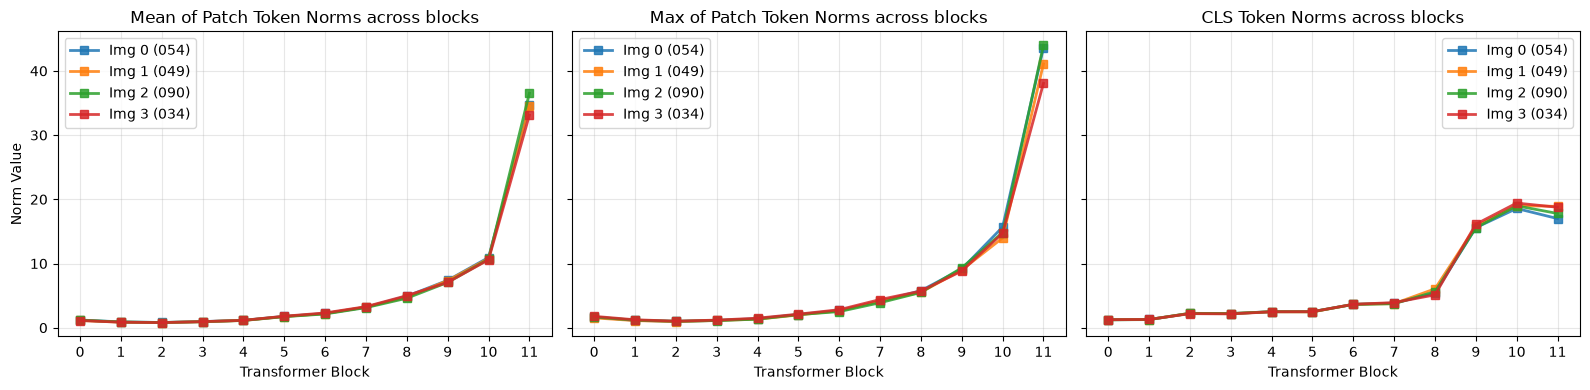

In [8]:
# Layer-wise feature extraction and analysis
intermediate_features = {}
hook_handles = []

def make_hook(block_idx: int):
    # output shape from block: (Batch, Num_Tokens, Embed_Dim)
    def hook(module, input_tensor, output_tensor):
        intermediate_features[block_idx] = output_tensor.detach().cpu()
    return hook

# 1. Register forward hooks on every block
for idx, block in enumerate(model.blocks):
    handle = block.register_forward_hook(make_hook(idx))
    hook_handles.append(handle)

# 2. Run model forward pass
model.eval()
with torch.no_grad():
    _ = model(imgs_tensor)

for handle in hook_handles:
    handle.remove()

patch_norms_max_list = []
patch_norms_mean_list = []
cls_norms_list = []

for idx, feats in intermediate_features.items():
    patch_norms = feats[:, 1:, :].norm(dim=-1)  # Norm of patch tokens
    # dinov2_vits14 has no reg tokens
    cls_norms = feats[:, 0, :].norm(dim=-1)      # Norm of cls token
    patch_norms_mean_list.append(patch_norms.mean(dim=1))
    patch_norms_max_list.append(patch_norms.max(dim=1).values)
    cls_norms_list.append(cls_norms)

    feats_next = intermediate_features.get(idx + 1, None)
    if feats_next is not None:
        cls_sim = torch.nn.functional.cosine_similarity(feats[:, 0, :], feats_next[:, 0, :], dim=-1)
        patch_sim = torch.nn.functional.cosine_similarity(feats[:, 1:, :], feats_next[:, 1:, :], dim=-1)
        print(f"Block {idx:2d} cosine similarity of cls token with next block: {cls_sim}")
        print(f"Block {idx:2d} cosine similarity of patch tokens with next block: {patch_sim.mean(dim=1)}")

n_layers = len(model.blocks)
layers_x = list(range(n_layers))

# Stack per-block (B,) tensors into (n_layers, B) arrays
patch_norms_mean = torch.stack(patch_norms_mean_list).numpy()  # (n_layers, B)
patch_norms_max = torch.stack(patch_norms_max_list).numpy()    # (n_layers, B)
cls_norms_arr = torch.stack(cls_norms_list).numpy()            # (n_layers, B)

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for img_idx, img_path in enumerate(paths):
    label = f"Img {img_idx} ({Path(img_path).stem})"
    axes[0].plot(layers_x, patch_norms_mean[:, img_idx], marker="s", linewidth=2, alpha=0.85, label=label)
    axes[1].plot(layers_x, patch_norms_max[:, img_idx], marker="s", linewidth=2, alpha=0.85, label=label)
    axes[2].plot(layers_x, cls_norms_arr[:, img_idx], marker="s", linewidth=2, alpha=0.85, label=label)

axes[0].set_title("Mean of Patch Token Norms across blocks")
axes[1].set_title("Max of Patch Token Norms across blocks")
axes[2].set_title("CLS Token Norms across blocks")
for ax in axes:
    ax.set_xlabel("Transformer Block")
    ax.set_xticks(layers_x)
    ax.grid(True, alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Norm Value")
plt.tight_layout()
plt.show()

In [ ]:
# Feature evaluation (k-NN + Logistic Regression)
seed = 42
batch_size = 4

csv_path = Path("../external/segmentation_WBC/Class Labels of Dataset 2.csv")
with open(csv_path, newline="") as f:
    id_to_class = {int(row["image ID"]): int(row["class"]) for row in csv.DictReader(f)}
img_dir = Path("../external/segmentation_WBC/Dataset 2")
all_paths = sorted(img_dir.glob("*.bmp"))
y = np.array([id_to_class[int(p.stem)] for p in all_paths])

class_names = {1: "neutrophil", 2: "lymphocyte", 3: "monocyte", 4: "eosinophil", 5: "basophil"}
class_counts = {int(k): int(v) for k, v in zip(*np.unique(y, return_counts=True))}
print("Class counts:", ", ".join(f"{k} ({class_names[k]}): {v}" for k, v in class_counts.items()))

model.to(device)
model.eval()

features_list = []
with torch.no_grad():
    for i in range(0, len(all_paths), batch_size):
        batch_imgs = [
            transform(Image.open(p).convert("RGB").resize((img_size, img_size)))
            for p in all_paths[i : i + batch_size]
        ]
        batch_tensor = torch.stack(batch_imgs).to(device)
        cls_feats = model.forward_features(batch_tensor)["x_norm_clstoken"]  # (B, 384)
        #cls_feats = F.normalize(cls_feats, dim=-1)  # L2-normalize
        features_list.append(cls_feats.cpu().numpy())
        
X = np.concatenate(features_list, axis=0)  # (100, 384)
print(f"Features shape: {X.shape}")

# Stratified to have same class proportions in train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=seed
)

for k in [1, 3, 5]:
    knn = KNeighborsClassifier(n_neighbors=k, metric="cosine")
    knn.fit(X_train, y_train)
    preds = knn.predict(X_test)
    print(
        f"k-NN (k={k}) | Acc: {accuracy_score(y_test, preds):.3f} | "
        f"Bal Acc: {balanced_accuracy_score(y_test, preds):.3f} | "
        f"Weighted F1: {f1_score(y_test, preds, average='weighted'):.3f}"
    )

clf = LogisticRegression(C=1.0, max_iter=1000, solver="lbfgs")
clf.fit(X_train, y_train)
preds = clf.predict(X_test)
print(
    f"LogReg     | Acc: {accuracy_score(y_test, preds):.3f} | "
    f"Bal Acc: {balanced_accuracy_score(y_test, preds):.3f} | "
    f"Weighted F1: {f1_score(y_test, preds, average='weighted'):.3f}"
)

Class counts: 1 (neutrophil): 33, 2 (lymphocyte): 37, 3 (monocyte): 15, 4 (eosinophil): 12, 5 (basophil): 3
Features shape: (100, 384)
k-NN (k=1) | Acc: 0.767 | Bal Acc: 0.742 | Weighted F1: 0.766
k-NN (k=3) | Acc: 0.800 | Bal Acc: 0.642 | Weighted F1: 0.789
k-NN (k=5) | Acc: 0.767 | Bal Acc: 0.592 | Weighted F1: 0.751
LogReg     | Acc: 0.800 | Bal Acc: 0.642 | Weighted F1: 0.792


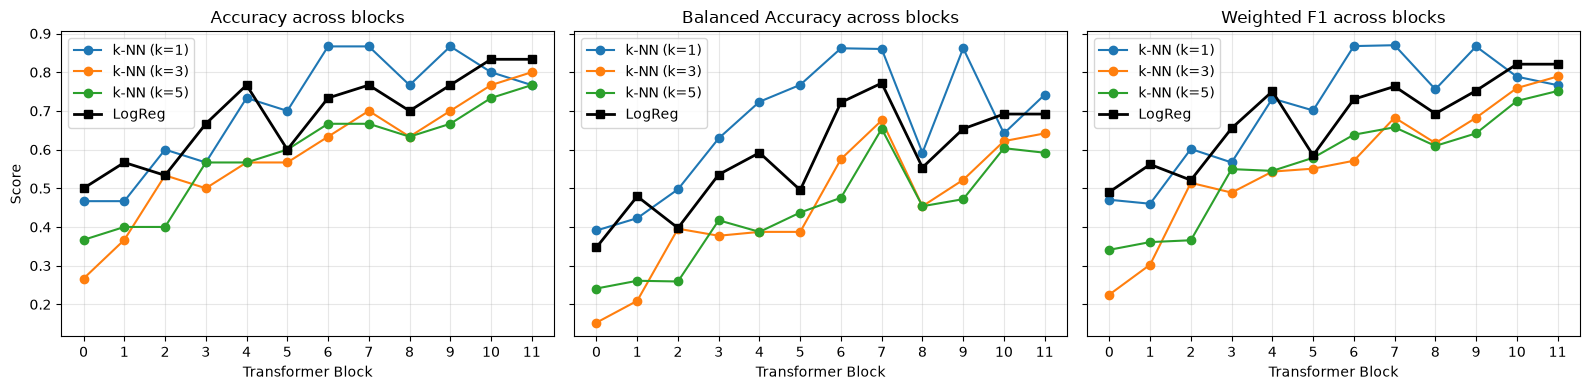

In [10]:
# Layer-wise CLS feature extraction and evaluation (k-NN + Logistic Regression)
n_layers = len(model.blocks)
layer_batches = [[] for _ in range(n_layers)]

model.to(device)
model.eval()
with torch.no_grad():
    for i in range(0, len(all_paths), batch_size):
        batch_imgs = [
            transform(Image.open(p).convert("RGB").resize((img_size, img_size)))
            for p in all_paths[i : i + batch_size]
        ]
        batch_tensor = torch.stack(batch_imgs).to(device)  # (B, 3, H, W)
        # Returns tuple of n_layers (patch_tokens: (B, N_p, C), cls_token: (B, C))
        layer_outputs = model.get_intermediate_layers(
            batch_tensor, n=n_layers, return_class_token=True, norm=True
        )
        for layer_idx, (_, cls_token) in enumerate(layer_outputs):
            layer_batches[layer_idx].append(cls_token.cpu().numpy())

X_layers = [np.concatenate(batches, axis=0) for batches in layer_batches]  # list of (100, 384)

# Shared stratified split indices so every layer is evaluated on the exact same split
train_idx, test_idx = train_test_split(
    np.arange(len(y)), test_size=0.3, stratify=y, random_state=seed
)
y_train, y_test = y[train_idx], y[test_idx]

knn_k_values = [1, 3, 5]
knn_acc = {k: [] for k in knn_k_values}
knn_bal_acc = {k: [] for k in knn_k_values}
knn_f1 = {k: [] for k in knn_k_values}
logreg_acc, logreg_bal_acc, logreg_f1 = [], [], []

for layer_idx, X_layer in enumerate(X_layers):
    X_train, X_test = X_layer[train_idx], X_layer[test_idx]

    knn_parts = []
    for k in knn_k_values:
        knn = KNeighborsClassifier(n_neighbors=k, metric="cosine")
        knn.fit(X_train, y_train)
        preds = knn.predict(X_test)
        acc = accuracy_score(y_test, preds)
        bal_acc = balanced_accuracy_score(y_test, preds)
        f1 = f1_score(y_test, preds, average="weighted")
        knn_acc[k].append(acc)
        knn_bal_acc[k].append(bal_acc)
        knn_f1[k].append(f1)
        knn_parts.append(f"k={k}: {acc:.3f}/{bal_acc:.3f}/{f1:.3f}")

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    clf = LogisticRegression(C=1.0, max_iter=1000, solver="lbfgs", random_state=seed)
    clf.fit(X_train_scaled, y_train)
    lr_preds = clf.predict(X_test_scaled)
    lr_acc = accuracy_score(y_test, lr_preds)
    lr_bal = balanced_accuracy_score(y_test, lr_preds)
    lr_f1 = f1_score(y_test, lr_preds, average="weighted")
    logreg_acc.append(lr_acc)
    logreg_bal_acc.append(lr_bal)
    logreg_f1.append(lr_f1)

# Plot layer-wise accuracy, balanced accuracy, and weighted F1
layers_x = list(range(n_layers))
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

for k in knn_k_values:
    axes[0].plot(layers_x, knn_acc[k], marker="o", label=f"k-NN (k={k})")
    axes[1].plot(layers_x, knn_bal_acc[k], marker="o", label=f"k-NN (k={k})")
    axes[2].plot(layers_x, knn_f1[k], marker="o", label=f"k-NN (k={k})")

axes[0].plot(layers_x, logreg_acc, marker="s", linewidth=2, color="black", label="LogReg")
axes[1].plot(layers_x, logreg_bal_acc, marker="s", linewidth=2, color="black", label="LogReg")
axes[2].plot(layers_x, logreg_f1, marker="s", linewidth=2, color="black", label="LogReg")

axes[0].set_title("Accuracy across blocks")
axes[1].set_title("Balanced Accuracy across blocks")
axes[2].set_title("Weighted F1 across blocks")
for ax in axes:
    ax.set_xlabel("Transformer Block")
    ax.set_xticks(layers_x)
    ax.grid(True, alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Score")
plt.tight_layout()
plt.show()

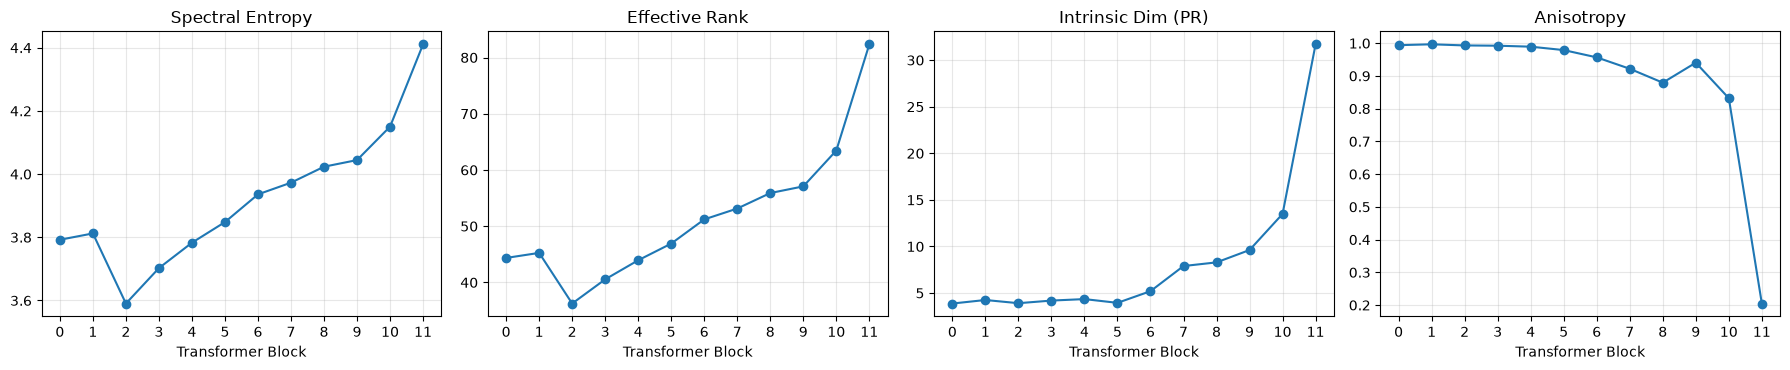

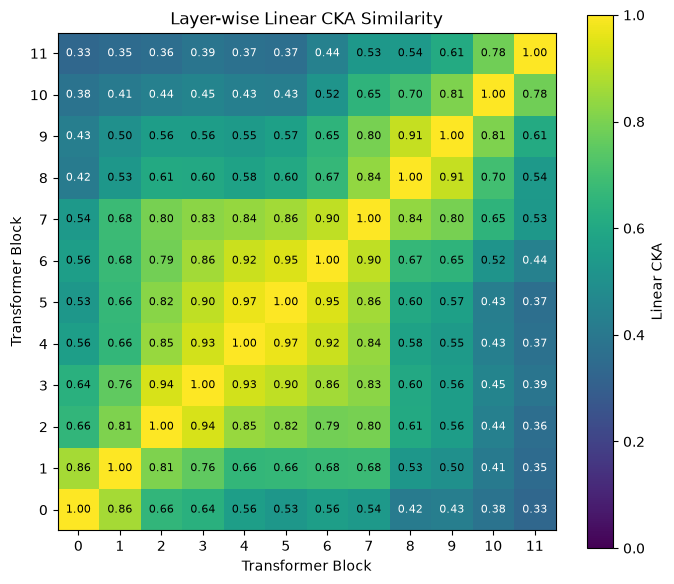

In [12]:
def layer_geometry_metrics(X: np.ndarray) -> dict[str, float]:
    n = X.shape[0]
    # 1. Anisotropy (uncentered mean pairwise cosine similarity)
    norms = np.linalg.norm(X, axis=1, keepdims=True)
    X_unit = X / np.maximum(norms, 1e-12)
    sim = X_unit @ X_unit.T
    anisotropy = float((sim.sum() - n) / (n * (n - 1)))
    # 2. Centered SVD spectrum -> Spectral Entropy, Effective Rank, Participation Ratio
    X_centered = X - X.mean(axis=0, keepdims=True)
    s = np.linalg.svd(X_centered, full_matrices=False, compute_uv=False)
    s = s[s > 1e-12]
    p = s / s.sum()
    spectral_entropy = float(-np.sum(p * np.log(p)))
    effective_rank = float(np.exp(spectral_entropy))
    eigvals = s ** 2
    participation_ratio = float((eigvals.sum() ** 2) / np.sum(eigvals ** 2))
    return {
        "spectral_entropy": spectral_entropy,
        "effective_rank": effective_rank,
        "id_pr": participation_ratio,
        "anisotropy": anisotropy,
    }
results = [layer_geometry_metrics(X_layer) for X_layer in X_layers]

# Plot across layers
layers_x = list(range(len(results)))
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, (key, title) in zip(
    axes,
    [
        ("spectral_entropy", "Spectral Entropy"),
        ("effective_rank", "Effective Rank"),
        ("id_pr", "Intrinsic Dim (PR)"),
        ("anisotropy", "Anisotropy"),
    ],
):
    ax.plot(layers_x, [r[key] for r in results], marker="o")
    ax.set_title(title)
    ax.set_xlabel("Transformer Block")
    ax.set_xticks(layers_x)
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Linear CKA similarity matrix across layers
def linear_cka(X: np.ndarray, Y: np.ndarray) -> float:
    # X, Y shape: (N, D)
    X_c = X - X.mean(axis=0, keepdims=True)
    Y_c = Y - Y.mean(axis=0, keepdims=True)
    hsic_xy = np.linalg.norm(X_c.T @ Y_c, ord="fro") ** 2
    hsic_xx = np.linalg.norm(X_c.T @ X_c, ord="fro")
    hsic_yy = np.linalg.norm(Y_c.T @ Y_c, ord="fro")
    return float(hsic_xy / (hsic_xx * hsic_yy))

n_layers_cka = len(X_layers)
cka_matrix = np.zeros((n_layers_cka, n_layers_cka), dtype=np.float64)
for i in range(n_layers_cka):
    for j in range(i, n_layers_cka):
        val = linear_cka(X_layers[i], X_layers[j])
        cka_matrix[i, j] = val
        cka_matrix[j, i] = val

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cka_matrix, origin="lower", cmap="viridis", vmin=0.0, vmax=1.0)
fig.colorbar(im, ax=ax, label="Linear CKA")
ax.set_title("Layer-wise Linear CKA Similarity")
ax.set_xlabel("Transformer Block")
ax.set_ylabel("Transformer Block")
ax.set_xticks(layers_x)
ax.set_yticks(layers_x)
for i in range(n_layers_cka):
    for j in range(n_layers_cka):
        val = cka_matrix[i, j]
        ax.text(
            j, i, f"{val:.2f}",
            ha="center", va="center", fontsize=8,
            color="white" if val < 0.5 else "black",
        )
plt.tight_layout()
plt.show()